# Phase 3: MuRIL + IndicBERT fine-tuning (Hindi)

Owner: Shreyank Sthavaramath. Plan: [docs/01-roadmap.md](../docs/01-roadmap.md), Phase 3.

Fine-tune **MuRIL** (primary) and **IndicBERT** (comparison) for Hindi NER with
HuggingFace `AutoModelForTokenClassification` + `Trainer`. The subword
label-alignment step is the #1 NER bug (see
[docs/05-pitfalls.md](../docs/05-pitfalls.md)); it gets its own section and a
self-test below before any model is trained on it.

**The training size is found from the data, not fixed up front.** Train at an
increasing sequence of subset sizes, score Hindi gold F1 after each, log every
point as its own row in the results sheet, and stop adding data once the
F1-vs-size curve flattens. That size becomes the working subset for the rest
of the project.

**Gate:** both models scored on Hindi gold; MuRIL clearly beats the
BiLSTM-CRF baseline (**0.8038**, Phase 2); the scaling curve is logged and a
working subset size is chosen from it. *If MuRIL does not beat the baseline,
suspect the label alignment first.*

**How to run (Kaggle)**
1. Commit and push this notebook to `phase3-muril-indicbert`, because the
   run clones that branch and records its commit.
2. Import it on Kaggle with **GPU T4 x2** and **Internet** on, and attach the
   `GH_TOKEN` (read-only) and `HF_TOKEN` (write) Secrets.
3. With `DEBUG = True`, use **Save & Run All**. This checks cloning, login,
   training, upload, reload, and scoring on ~80 sentences. Its scores are
   meaningless, so do not keep its `results.csv`.
4. Set `DEBUG = False` and use **Save & Run All** again (about 4 hours). This
   one run does the 10k diagnosis, scaling curve, extra seeds, size choice,
   IndicBERT comparison, and handoff verification.
5. Download `NaamRekha/results/results.csv` and
   `NaamRekha/results/phase3_scaling_curve.png` from the version's Output tab,
   plus the executed notebook. Do not edit their contents.
6. Check the gate with `uv run python scripts/phase3_gate.py` (from the repo
   root, locally -- it only reads `results/results.csv` and this notebook,
   no GPU needed).

In [1]:
# Pin versions (docs/04-compute.md). Colab/Kaggle ship their own torch;
# transformers/datasets/accelerate/seqeval/sentencepiece are pinned here so
# runs are reproducible across machines.
%pip install -q transformers==5.22.1 datasets==5.1.0 accelerate==1.15.0 seqeval==1.2.2 sentencepiece==0.2.2  # Jupyter "magic" command: pip-installs these exact pinned versions into the running kernel so transformers/datasets/accelerate/seqeval/sentencepiece match across Kaggle, Colab, and local runs

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import base64  # standard library: used below to base64-encode the GitHub token into an HTTP Basic auth header for the git clone
import os  # standard library: used for path checks, environment variables, and directory creation throughout this cell
import subprocess  # standard library: used to shell out to `git clone` and `git rev-parse` so the notebook can self-bootstrap the repo
import sys  # standard library: used to prepend the repo root to sys.path so `from src import ...` resolves

REPO_URL = "https://github.com/iPriyadarshi/NaamRekha.git"  # HTTPS clone URL of this project's GitHub repo, used only when running on Kaggle/Colab where the repo isn't already present
REPO_BRANCH = "phase3-muril-indicbert"  # the branch this notebook belongs to; Kaggle clones exactly this branch so the run matches the code that was committed


def get_secret(name):  # looks up a named secret (e.g. GH_TOKEN, HF_TOKEN) across whichever platform this notebook happens to be running on
    # Kaggle Secret, then Colab Secret, then environment variable.
    try:  # first try Kaggle's secrets vault, since that's where this notebook is meant to run for real training
        from kaggle_secrets import UserSecretsClient  # this import only succeeds inside a Kaggle kernel
        return UserSecretsClient().get_secret(name)  # fetch the named secret from Kaggle's attached Secrets (e.g. GH_TOKEN, HF_TOKEN)
    except Exception:  # not running on Kaggle (or secret not attached) -- fall through to the next source
        pass  # swallow the error and continue to the Colab branch below
    try:  # next try Google Colab's userdata secret store
        from google.colab import userdata  # this import only succeeds inside a Colab runtime
        return userdata.get(name)  # fetch the named secret from Colab's userdata API
    except Exception:  # not running on Colab either -- fall back to a plain environment variable
        return os.environ.get(name)  # local/dev fallback: read the secret from the process environment (e.g. a .env file), or None if unset


# Local: the notebook runs from notebooks/, so the repo root is "..".
# Colab/Kaggle: clone the repo next to the notebook. Check for a repo file, not
# just src/, because Kaggle has its own unrelated /kaggle/src folder.
if os.path.isfile("../src/data.py"):  # running from notebooks/ with the repo already checked out one directory up (the normal local layout)
    REPO_ROOT = os.path.abspath("..")  # repo root is the parent directory of notebooks/
elif os.path.isfile("src/data.py"):  # or the notebook has been moved so the repo root IS the current directory
    REPO_ROOT = os.path.abspath(".")  # repo root is the current working directory
else:  # neither local layout found -- assume we're on Kaggle/Colab where the repo must be cloned fresh
    REPO_ROOT = os.path.abspath("NaamRekha")  # the clone will be placed in a NaamRekha/ folder next to the notebook
    if not os.path.isdir(REPO_ROOT):  # only clone if that folder doesn't already exist (so re-running this cell doesn't reclone)
        env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}  # copy the current environment and disable git's interactive credential prompt, so a missing/bad token fails fast instead of hanging
        token = get_secret("GH_TOKEN")  # fetch the read-only GitHub token (attached as a Kaggle/Colab secret) used to authenticate the clone
        if token:  # only build an auth header if a token was actually found
            # Passed through the environment so it is never saved in .git/config
            # (Kaggle keeps that folder as output) or printed if the clone fails.
            auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()  # build the base64 payload for an HTTP Basic 'x-access-token:<token>' credential, the format git expects for a bearer-style GitHub token over HTTPS
            env.update(GIT_CONFIG_COUNT="1",  # inject one extra git config value via environment variables rather than writing a credential to disk
                       GIT_CONFIG_KEY_0="http.https://github.com/.extraheader",  # the config key being set: an extra HTTP header git attaches to every request to github.com
                       GIT_CONFIG_VALUE_0=f"AUTHORIZATION: basic {auth}")  # the config value: the actual 'Authorization: Basic <base64>' header carrying the token
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, REPO_ROOT],  # shallow-clone (depth 1) just the target branch into REPO_ROOT, using the auth header set above if present
                       check=True, env=env)  # raise immediately if the clone fails, using the environment (with the injected auth header) built above
sys.path.insert(0, REPO_ROOT)  # make the repo's `src` package importable regardless of which of the three layouts above was used

# indic-bert is gated, and every run publishes its checkpoint to the Hub.
hf_token = get_secret("HF_TOKEN")  # Hugging Face token (write access) needed to download gated models like ai4bharat/indic-bert and to push trained checkpoints
if hf_token:  # only set it if a token was actually found (e.g. local runs without training don't need one)
    os.environ["HF_TOKEN"] = hf_token  # export it so huggingface_hub/transformers pick it up automatically for auth

GIT_COMMIT = subprocess.check_output(["git", "-C", REPO_ROOT, "rev-parse", "--short", "HEAD"], text=True).strip()  # record the short commit hash of the checked-out code; it gets stamped into every results.csv row so each score traces back to the exact code that produced it

from src import LABELS, evaluate, id2label, label2id, load_split, log_result, tag_distribution  # import this project's shared NER utilities now that REPO_ROOT is on sys.path: label vocabulary, the seqeval-based scorer, data loaders, and the results-logging helper

print("repo:", REPO_ROOT, "| commit:", GIT_COMMIT)  # sanity-check output: confirm which repo copy and which commit this run is actually using
print("labels:", LABELS)  # sanity-check output: confirm the NER label set (e.g. O, B-PER, I-PER, ...) matches expectations before training starts


Cloning into '/kaggle/working/NaamRekha'...


repo: /kaggle/working/NaamRekha | commit: 77b5e99
labels: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


## Config

Every knob is in this one cell. Each `train_run()` call records its settings
in the results-row `notes` automatically.

In [3]:
SEED = 42  # master random seed for this run; reused for Python's random, NumPy, and torch so subset sampling and training are reproducible
LANG = "hi"  # this phase only trains/evaluates Hindi ('hi'); other languages are handled in later phases

DEBUG = False    # True: ~80 sentences, 1 epoch (pipeline check). False: real runs on Kaggle.

# Kaggle's dual-T4 sessions otherwise wrap the model in DataParallel, silently
# doubling the effective batch size below. Force single-GPU so BATCH_SIZE is
# the real one (must be set before torch is imported/initializes CUDA).
import os  # re-import os here (already imported at kernel level) purely so CUDA_VISIBLE_DEVICES can be set immediately below, before torch ever touches the GPU
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # restrict the process to GPU 0 only, so Kaggle's second T4 is invisible and Trainer can't silently wrap the model in DataParallel

# MuRIL is the primary model (roadmap). IndicBERT is the comparison model.
MODELS = {  # mapping from a short model key used throughout this notebook to its actual Hugging Face Hub checkpoint id
    "MuRIL": "google/muril-base-cased",  # Google's multilingual model pretrained specifically on Indian languages; this is the model being scaled up in this phase
    "IndicBERT": "ai4bharat/indic-bert",  # AI4Bharat's Indic-language model, trained only once at the chosen subset size, as a comparison point
}  # end of the MODELS mapping

MAX_LENGTH = 128      # subword tokens per sentence (docs/04-compute.md: NER sentences are short)
BATCH_SIZE = 32  # per-device training batch size in sentences; combined with CUDA_VISIBLE_DEVICES=0 this is also the true effective batch size
EVAL_BATCH_SIZE = 32  # batch size used only for inference/scoring (predict_tags), kept separate from the training batch size for clarity
LR = 2e-5  # peak learning rate for fine-tuning; a small value typical for transformer fine-tuning so pretrained weights aren't destroyed
EPOCHS = 3  # number of full passes over the training subset for the standard scaling-curve runs

# Scaling ladder (roadmap: "10k, then roughly triple each step"). 900k was
# never completed in a Kaggle session, so it's dropped from the ladder.
SUBSET_SIZES = [10_000, 30_000, 100_000, 300_000]  # the sequence of training-set sizes used to trace the F1-vs-data-size scaling curve, each roughly 3x the previous

# Size choice: repeat these sizes on the extra seeds, then pick the smallest size
# with no collapsed seed whose mean validation F1 is within SIZE_TOLERANCE of the best.
SEEDED_SIZES = [30_000, 100_000]  # which sizes from the ladder get repeated on extra seeds, to measure run-to-run variance before picking a final size
EXTRA_SEEDS = [43, 44]  # two additional seeds (besides the master SEED=42) used to check that a chosen size's F1 isn't a lucky/unlucky fluke
SIZE_TOLERANCE = 0.01  # how close (in absolute F1) a smaller size's mean validation score must be to the best size's score to still count as 'good enough', favoring smaller/cheaper training sizes
COLLAPSE_F1 = 0.1     # validation F1 below this counts as a collapsed run

HF_PRIVATE = True     # visibility of the checkpoint repos created on the Hub

if DEBUG:  # override the real settings above with a tiny, fast configuration when doing a pipeline smoke-test
    SUBSET_SIZES = [80]  # train on just 80 sentences so the whole pipeline runs in seconds/minutes instead of hours
    EPOCHS = 1  # a single epoch is enough to prove the training loop runs end-to-end; the resulting score is meaningless
    BATCH_SIZE = 8  # a small batch size so the debug run also works on CPU or a tiny GPU without running out of memory



In [4]:
def pick_storage() -> str:  # decide where trained checkpoints are written so they survive across a session (Kaggle's working dir is wiped between sessions; Drive/local checkpoints/ are not)
    # Persistent storage for checkpoints: Kaggle working dir, Google Drive, or local checkpoints/.
    if os.path.isdir("/kaggle/working"):  # detect that we're running inside a Kaggle kernel, which always has this working directory
        return "/kaggle/working/naamrekha"  # Kaggle persists /kaggle/working as the session's Output, so checkpoints saved here survive until the version finishes
    try:  # not on Kaggle -- try mounting Google Drive instead, for Colab persistence
        from google.colab import drive  # type: ignore  # only importable inside a Colab runtime; the type: ignore silences a missing-stub warning from the type checker
        drive.mount("/content/drive")  # prompts the user (interactively) to authorize and mount their Google Drive at /content/drive
        return "/content/drive/MyDrive/NaamRekha"  # store checkpoints in the user's Drive so they aren't lost when the Colab runtime recycles
    except ImportError:  # neither Kaggle nor Colab -- must be a local/dev environment
        return os.path.join(REPO_ROOT, "checkpoints")  # fall back to a checkpoints/ folder inside the repo itself


STORAGE = pick_storage()  # resolve the storage root once for this run, using whichever platform was detected above
os.makedirs(os.path.join(STORAGE, "phase3"), exist_ok=True)  # ensure the phase3 subfolder exists before any checkpoint is written into it
print("checkpoints ->", os.path.join(STORAGE, "phase3"))  # log the resolved checkpoint path so it's visible in the executed notebook's output

checkpoints -> /kaggle/working/naamrekha/phase3


In [5]:
import random  # Python's standard PRNG, seeded below and used by make_subset for reproducible subsetting

import numpy as np  # NumPy, seeded below for reproducibility in any numeric code that depends on its global RNG
import torch  # PyTorch, the deep-learning framework used for model training/inference in this notebook

random.seed(SEED)  # seed Python's random module so make_subset's sampling is reproducible run to run
np.random.seed(SEED)  # seed NumPy's global RNG for the same reason
torch.manual_seed(SEED)  # seed PyTorch's CPU RNG, affecting weight initialization and any CPU-side randomness
torch.cuda.manual_seed_all(SEED)  # seed PyTorch's CUDA RNG on all visible GPUs, for reproducible GPU-side randomness (e.g. dropout)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # pick the GPU if one is visible, otherwise fall back to CPU
print("torch", torch.__version__, "| device:", device, "| GPU count:", torch.cuda.device_count())  # log the torch version, chosen device, and GPU count so the executed notebook records what hardware actually ran this
if device.type == "cpu":  # warn loudly if no GPU was found, since transformer fine-tuning on CPU is impractically slow for anything beyond DEBUG
    print("WARNING: no GPU. Fine for DEBUG, too slow for the real scaling runs -- use Kaggle.")  # the actual warning message printed when running on CPU
if not DEBUG and torch.cuda.device_count() != 1:  # guard against accidentally running a real (non-DEBUG) job with zero or more than one visible GPU, which would break the effective-batch-size assumption
    raise RuntimeError(f"real runs need exactly one visible GPU, found {torch.cuda.device_count()}")  # fail fast with a clear message rather than silently training with the wrong effective batch size



torch 2.11.0+cu130 | device: cuda | GPU count: 1


## Data

Train on **silver**, evaluate on the full **gold** test set, per
[docs/03-conventions.md](../docs/03-conventions.md). `make_subset` draws a
seeded random subset (same recipe as Phase 2) and `entity_report` checks it
is not mostly `O`, per the subset rule in that doc.

In [6]:
train_full = load_split(LANG, "train")  # load the full Hindi silver-labeled training set (every sentence, before any subsetting)
val = load_split(LANG, "val")  # load the Hindi validation split, used for model-selection decisions (choosing subset size, checking for collapse)
test = load_split(LANG, "test")  # load the Hindi gold test set -- the one and only set used for the final reported F1
print(f"train {len(train_full):,} (full silver) | val {len(val):,} | test {len(test):,} (gold)")  # log the three split sizes so it's obvious at a glance how much data each represents


def make_subset(rows, n, seed=SEED):  # draw a reproducible random subset of n rows from a larger list of (words, tags) sentence pairs
    n = min(n, len(rows))  # never ask for more rows than actually exist (e.g. a SUBSET_SIZES entry larger than train_full)
    idx = sorted(random.Random(seed).sample(range(len(rows)), n))  # pick n unique row indices with a seed-specific RNG (so each seed gets a different, but reproducible, sample) and sort them to keep the original sentence order
    return [rows[i] for i in idx]  # materialize the subset by indexing into the original rows


def entity_report(rows, name):  # print a quick sanity summary of a set of rows: how many of each entity type, and what fraction of tokens/sentences actually contain an entity
    counts = tag_distribution(rows)  # tally how many tokens carry each BIO tag (e.g. 'O', 'B-PER', 'I-ORG', ...) across these rows
    total = sum(counts.values())  # total token count across all tags, used as the denominator for the 'O' percentage below
    ents = {t: counts.get(f"B-{t}", 0) for t in ("PER", "ORG", "LOC")}  # count of entity *spans* per type, approximated by counting B- (begin) tags for PER/ORG/LOC
    with_ent = sum(any(t != "O" for t in tags) for _, tags in rows)  # number of sentences that contain at least one non-'O' tag, i.e. at least one entity mention
    print(f"{name}: entities {ents} | O = {counts['O'] / total:.1%} of tokens | "  # print the entity counts and what fraction of tokens are the non-entity 'O' tag
          f"{with_ent / len(rows):.1%} of sentences have >=1 entity")  # continuation of the same print: what fraction of sentences have at least one entity, guarding against a subset that is almost entirely background 'O' tokens


entity_report(test, "gold test (fixed, never subset)")  # run the sanity check once on the fixed gold test set, which (unlike train) is never subsetted

data/hi_IndicNER_v1.0.zip: reconstructing file:   0%|          |  0.00B / 82.3MB            

data/hi_IndicNER_v1.0.zip: downloading bytes:           |  0.00B            

train 985,787 (full silver) | val 13,460 | test 864 (gold)
gold test (fixed, never subset): entities {'PER': 788, 'ORG': 521, 'LOC': 613} | O = 83.0% of tokens | 86.0% of sentences have >=1 entity


## Subword label alignment

The #1 NER bug with BERT-family models: each tokenizer splits a word into
one or more subword pieces, but we have one label per **word**. The rule
(docs/05-pitfalls.md): label only the first subword of each word with that
word's tag; every continuation subword and every special token (`[CLS]`,
`[SEP]`, padding) gets `-100` so the loss ignores it. `word_ids()` is what
makes this mapping possible. IndicBERT's SentencePiece tokenizer can emit a
standalone `▁` as a word's first piece, which holds no text, so the label goes
on the first real piece after it.

A self-test below checks this on a real training sentence *before* any
model is trained on it.

In [7]:
from datasets import Dataset  # Hugging Face's `datasets` library, used to wrap the raw (words, tags) rows into a Dataset the Trainer API expects


def label_positions(word_ids, tokens):  # compute, for each original word, which single subword *position* should carry that word's label
    # word -> position of the subword that carries its label: the first piece,
    # skipping a standalone SentencePiece "▁" when a real piece follows it.
    positions = {}  # maps a word index (from word_ids) to the chosen subword position for its label
    for pos, wid in enumerate(word_ids):  # walk every subword position alongside the word index it came from (None for special tokens)
        if wid is not None and (wid not in positions or tokens[positions[wid]] == "▁"):  # real word subword, and either we haven't picked a position for this word yet, or the one we picked so far is a bare '▁' placeholder that should be replaced by a real piece
            positions[wid] = pos  # record this subword position as the (current best) label-carrying position for word wid
    return positions  # hand back the word -> label-position mapping built above


def tokenize_and_align_labels(batch, tokenizer, max_length=MAX_LENGTH):  # tokenize a batch of word-tokenized sentences into subwords and build a matching, correctly-aligned label array for each
    enc = tokenizer(batch["words"], is_split_into_words=True, truncation=True, max_length=max_length)  # subword-tokenize already word-split input (is_split_into_words=True preserves the word boundaries the tokenizer needs for word_ids())
    all_labels = []  # will hold one list of subword-level label ids per sentence in the batch
    for i, tags in enumerate(batch["tags"]):  # process each sentence's gold word-level tags in turn, i being its position in the batch
        word_ids = enc.word_ids(batch_index=i)  # for this sentence, the subword-position -> original-word-index mapping (None for special tokens) that the tokenizer records
        labeled = set(label_positions(word_ids, enc.tokens(batch_index=i)).values())  # the specific subword positions (not word indices) that should receive a real label for this sentence
        label_ids = []  # subword-level label ids being built for this sentence, same length as word_ids
        for pos, wid in enumerate(word_ids):  # walk every subword position in this sentence
            if wid is None:  # a special token ([CLS], [SEP]) or padding -- has no corresponding word
                label_ids.append(-100)          # [CLS] / [SEP] / padding
            elif pos in labeled:  # this is the one chosen subword that should carry word wid's label
                label_ids.append(label2id[tags[wid]])   # labeled subword of this word
            else:  # a continuation subword of a word that was already labeled at an earlier position
                label_ids.append(-100)          # other subword
        all_labels.append(label_ids)  # store this sentence's finished label-id list
    enc["labels"] = all_labels  # attach the aligned labels to the tokenizer output so Trainer can read them alongside input_ids/attention_mask
    return enc  # hand back the batch encoding, now including the labels field


def to_hf_dataset(rows, tokenizer, max_length=MAX_LENGTH):  # convert this project's (words, tags) row format into a tokenized Hugging Face Dataset ready for Trainer
    ds = Dataset.from_dict({"words": [r[0] for r in rows], "tags": [r[1] for r in rows]})  # build a Dataset with one 'words' and one 'tags' column, pulled out of the (words, tags) tuples
    return ds.map(lambda b: tokenize_and_align_labels(b, tokenizer, max_length),  # apply the tokenize-and-align function to every row, in batches, via Dataset.map
                  batched=True, remove_columns=["words", "tags"])  # process in batches for speed, and drop the now-unneeded raw words/tags columns from the result

In [8]:
from transformers import AutoTokenizer  # Hugging Face's auto-tokenizer loader, used here to load MuRIL's and IndicBERT's own tokenizers for the self-test

for _model_key, _checkpoint in MODELS.items():  # run the label-alignment self-test once per model, since MuRIL and IndicBERT use different tokenizers with different subword behavior
    _tok = AutoTokenizer.from_pretrained(_checkpoint)  # load this model's tokenizer from the Hub
    _sample_words, _sample_tags = train_full[0]  # grab the very first training sentence as a concrete, known example to check alignment against
    _check_ds = to_hf_dataset([train_full[0]], _tok)  # run that single sentence through the real tokenize_and_align_labels pipeline, exactly as training will
    _enc_check = _tok(_sample_words, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)  # tokenize the same sentence directly (outside the dataset pipeline) so we have raw access to word_ids()/tokens() for the checks below
    _word_ids_check = _enc_check.word_ids()  # subword-position -> word-index mapping for this sentence, used to replay the alignment logic manually
    _labels_check = _check_ds[0]["labels"]  # the label ids the real pipeline actually produced for this sentence, which the assertions below will verify

    assert len(_labels_check) == len(_word_ids_check)  # basic sanity check: one label id per subword position, no off-by-one
    _labeled = set(label_positions(_word_ids_check, _enc_check.tokens()).values())  # recompute, independently, which subword positions should be labeled, to cross-check against what the pipeline actually did
    for _pos, _wid in enumerate(_word_ids_check):  # walk every subword position in this one sentence
        if _wid is None:  # a special token position
            assert _labels_check[_pos] == -100, "special token must be -100"  # verify special tokens are always ignored by the loss (-100)
        elif _pos in _labeled:  # the chosen label-carrying subword for its word
            assert _labels_check[_pos] == label2id[_sample_tags[_wid]], "labeled subword must carry the word's tag"  # verify it carries exactly the gold tag for that word, converted to its integer id
        else:  # a continuation subword, not the chosen one
            assert _labels_check[_pos] == -100, "other subwords must be -100"  # verify continuation subwords are also ignored by the loss

    print(f"label-alignment self-test ({_model_key}, {_checkpoint}): PASSED "  # report success for this model, including how many words expanded into how many subword positions
          f"({len(_sample_words)} words -> {len(_word_ids_check)} subword positions)")  # continuation of the same print: the word-count-to-subword-count ratio, a quick eyeball check that subword splitting is happening as expected

    # A standalone "▁" should only carry a label if the word has no other piece.
    _words_total = _bare_first = _bare_labeled = 0  # counters for the broader check below: total words seen, how many started with a bare '▁' piece, and how many of those still ended up carrying the label
    for _words, _ in make_subset(train_full, min(2000, len(train_full))):  # scan up to 2000 training sentences (not just the one sample) to measure how common the bare-'▁'-first-piece case actually is
        _enc = _tok(_words, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)  # tokenize this sentence the same way training will
        _pieces, _ids = _enc.tokens(), _enc.word_ids()  # the subword strings and their word-index mapping for this sentence
        _bare_first += sum(_pieces[_ids.index(_w)] == "▁" for _w in set(_ids) - {None})  # for every distinct real word in this sentence, check whether its very first subword occurrence is a bare SentencePiece '▁' marker, and tally how often that happens
        for _p in label_positions(_ids, _pieces).values():  # walk the actual label-carrying positions chosen by label_positions for this sentence
            _words_total += 1  # count one more word processed, for the final ratio
            _bare_labeled += _pieces[_p] == "▁"  # tally how often the *chosen* label-carrying position is still a bare '▁' (which would be a bug, since '▁' holds no real text)
    print(f"  standalone '▁' as first subword: {_bare_first} / {_words_total} words; "  # report how often a bare '▁' appears as a word's first piece
          f"still carrying the label: {_bare_labeled}")  # continuation: and, crucially, confirm it's essentially never still the one carrying the label (label_positions should have skipped past it)



config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

label-alignment self-test (MuRIL, google/muril-base-cased): PASSED (30 words -> 36 subword positions)
  standalone '▁' as first subword: 0 / 43545 words; still carrying the label: 0


config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/5.65M [00:00<?, ?B/s]

Map:   0%|          | 0/1 [00:00<?, ? examples/s]

label-alignment self-test (IndicBERT, ai4bharat/indic-bert): PASSED (30 words -> 44 subword positions)
  standalone '▁' as first subword: 1254 / 43423 words; still carrying the label: 0


## Prediction and scoring

Same evaluator as every other phase (`src.eval.evaluate`, entity-level
`seqeval` micro-F1). Predictions are mapped back from subwords to words the
same way the labels were built: only each word's labeled subword is read,
and every other position is skipped. Words lost to
truncation stay in the gold labels and count as predicted `O`, so a truncated
entity is scored as a miss.

In [9]:
def predict_tags(model, tokenizer, rows, max_length=MAX_LENGTH, batch_size=EVAL_BATCH_SIZE):  # run a fine-tuned model over a list of (words, tags) rows and return gold vs. predicted word-level tag sequences, ready for seqeval scoring
    model.eval()  # switch to evaluation mode (disables dropout, uses running batch-norm stats) for deterministic inference
    dev = next(model.parameters()).device  # find out which device (cpu/cuda) the model's weights currently live on, so inputs can be moved to match
    y_true, y_pred = [], []  # accumulators: gold tag sequences and predicted tag sequences, one list per sentence, across the whole dataset
    for i in range(0, len(rows), batch_size):  # process rows in fixed-size batches for efficient GPU inference
        chunk = rows[i:i + batch_size]  # the current slice of (words, tags) rows being predicted
        words_batch = [r[0] for r in chunk]  # just the word lists for this batch, what the tokenizer needs
        tags_batch = [r[1] for r in chunk]  # just the gold tag lists for this batch, kept aside to compare against predictions
        enc = tokenizer(words_batch, is_split_into_words=True, truncation=True, max_length=max_length,  # tokenize the whole batch at once, preserving word boundaries for word_ids()
                         padding=True, return_tensors="pt").to(dev)  # pad all sentences in the batch to equal length, return PyTorch tensors, and move them onto the model's device
        with torch.no_grad():  # disable gradient tracking during inference, saving memory and compute since no backward pass is needed
            logits = model(**enc).logits  # run the forward pass; logits has shape (batch, subword_position, num_labels)
        preds = logits.argmax(-1).cpu().numpy()  # take the highest-scoring label id at every subword position, then move the result to CPU/NumPy for easy indexing
        for b, tags in enumerate(tags_batch):  # walk each sentence in the batch, b being its index within this batch
            pred_tags = ["O"] * len(tags)  # start with an all-'O' prediction the same length as the gold tags; only labeled subword positions will overwrite entries below
            for wid, pos in label_positions(enc.word_ids(batch_index=b), enc.tokens(batch_index=b)).items():  # walk each word's chosen label-carrying subword position, the exact same alignment rule used during training
                pred_tags[wid] = id2label[int(preds[b][pos])]  # overwrite that word's prediction with the model's predicted tag at its labeled subword position; words with no labeled position (e.g. truncated away) stay 'O'
            y_pred.append(pred_tags)  # store this sentence's word-level predicted tag sequence
            y_true.append(list(tags))  # store this sentence's gold tag sequence alongside it, for seqeval to compare
    return y_true, y_pred  # hand back parallel lists of gold and predicted tag sequences, in the format src.eval.evaluate expects


for _model_key, _checkpoint in MODELS.items():  # check, per model, how many gold test sentences actually exceed the token budget
    _tok = AutoTokenizer.from_pretrained(_checkpoint)  # load this model's tokenizer to measure true subword length
    _long = sum(1 for words, _ in test if len(_tok(words, is_split_into_words=True)["input_ids"]) > MAX_LENGTH)  # count test sentences whose untruncated subword length exceeds MAX_LENGTH -- these will have their tail words silently scored as predicted 'O'
    print(f"{_model_key}: gold test sentences with > {MAX_LENGTH} subword tokens "  # report that count so it's clear how much of the gold F1 could be affected by truncation
          f"(tail words count as predicted O): {_long} / {len(test)}")  # continuation: show it as a fraction of the full gold test set size


MuRIL: gold test sentences with > 128 subword tokens (tail words count as predicted O): 0 / 864
IndicBERT: gold test sentences with > 128 subword tokens (tail words count as predicted O): 4 / 864


## Reusable training run

One function, called once per run. It samples the subset, checks entity
density, fine-tunes with HuggingFace `Trainer` (checkpointing every epoch so
a Kaggle disconnect only costs the current step), and scores on validation
and the full gold test set.

The order after training is fixed: **upload the final model and tokenizer,
confirm the upload, log one `results.csv` row with the pinned link, and only
then delete the local copy.** If the upload fails, the run stops and the local
folder stays. `run_name` contains a config hash, so a run can only resume from
a checkpoint made with identical settings.

In [10]:
import gc  # Python's garbage collector module, used after each run to help release GPU memory held by the just-finished model/trainer
import hashlib  # used to build a short deterministic hash of each run's config, so a run can be identified and resumed safely
import json  # used to serialize the config dict into a canonical string before hashing it
import math  # used for math.ceil when computing the number of optimizer steps per epoch
import shutil  # used to delete a run's local checkpoint directory once it has been safely uploaded to the Hub

import transformers  # imported for its __version__, which gets stamped into each run's results.csv row for reproducibility
from huggingface_hub import HfApi  # low-level Hugging Face Hub client, used to create model repos and upload checkpoint folders
from transformers import (  # pull in the pieces needed to build and run a token-classification fine-tuning job
    AutoModelForTokenClassification,  # loads any of MuRIL/IndicBERT with a token-classification (NER) head on top
    DataCollatorForTokenClassification,  # batches variable-length tokenized examples together, padding inputs and labels consistently
    Trainer,  # Hugging Face's high-level training loop, handling the optimizer, scheduler, checkpointing, and logging
    TrainerCallback,  # base class used below to hook custom behavior (per-epoch validation F1) into Trainer's training loop
    TrainingArguments,  # configuration object describing how Trainer should run (epochs, batch size, learning rate schedule, checkpointing, ...)
)  # end of the multi-line transformers import

hf_api = HfApi()  # a reusable Hub API client for creating repos and uploading files
HF_NAMESPACE = hf_api.whoami()["name"]   # fails here, before any training, if HF_TOKEN is missing
RUNS = []   # MuRIL runs that count towards the curve and the size choice


class ValF1Callback(TrainerCallback):  # a Trainer callback that scores validation F1 at the end of every epoch, so progress can be watched without waiting for the whole run to finish
    def __init__(self, tokenizer):  # set up per-callback-instance state
        self.tokenizer = tokenizer  # keep the tokenizer so predict_tags can be called on the validation set during training
        self.history = []  # running list of per-epoch validation F1 scores (as strings), later joined into the results-row notes

    def on_epoch_end(self, args, state, control, model=None, **kwargs):  # Trainer calls this automatically after every training epoch completes
        f1 = evaluate(*predict_tags(model, self.tokenizer, val))["F1_overall"]  # run the model (still in whatever mode Trainer left it in) over the validation set and score it
        self.history.append(f"{f1:.4f}")  # record this epoch's F1 for later auditing in the results notes
        print(f"epoch {state.epoch:.0f}: val F1 {f1:.4f}")  # print progress so it's visible live, and preserved in the executed notebook's output
        model.train()  # predict_tags leaves the model in eval() mode -- switch it back to train() so Trainer's next epoch has dropout etc. active again


def publish_checkpoint(ckpt_dir, run_name):  # upload a finished checkpoint folder to the Hugging Face Hub and verify the upload actually landed before trusting it
    repo_id = f"{HF_NAMESPACE}/naamrekha-{run_name}"  # the Hub repo id this run's checkpoint will live under, namespaced to the current user/org and this run's unique name
    hf_api.create_repo(repo_id, private=HF_PRIVATE, exist_ok=True)  # create the model repo if it doesn't already exist, respecting the configured visibility
    commit = hf_api.upload_folder(repo_id=repo_id, folder_path=ckpt_dir,  # upload every file in the checkpoint directory to the Hub repo in one commit
                                  ignore_patterns=["checkpoint-*", "runs/*"])  # skip Trainer's intermediate checkpoint-N/ subfolders and TensorBoard runs/ logs -- only the final saved model is needed on the Hub
    remote = {f.rfilename: f.size for f in hf_api.model_info(repo_id, revision=commit.oid, files_metadata=True).siblings}  # ask the Hub what actually landed at this exact commit: a map from uploaded filename to its reported byte size
    local_size = os.path.getsize(os.path.join(ckpt_dir, "model.safetensors"))  # the local weights file's size, used as the thing to compare against the remote copy
    if remote.get("model.safetensors") != local_size:  # the single most important check in this function: did the uploaded weights file actually match what we have locally?
        raise RuntimeError(f"upload to {repo_id} not confirmed; keeping {ckpt_dir}")  # fail loudly rather than deleting the only good copy of the weights -- the local checkpoint is left on disk for inspection/retry
    return repo_id, commit.oid  # hand back the Hub repo id and the exact commit (revision) that was verified, so later cells can pin to this precise checkpoint


def train_run(model_key, subset_size, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, seed=SEED, resume=True):  # the single reusable entry point for every training run in this phase: sample data, fine-tune, score, publish, and log one results row
    checkpoint = MODELS[model_key]  # resolve the short model key (e.g. 'MuRIL') to its actual Hub checkpoint id
    random.seed(seed)  # re-seed Python's RNG with this specific run's seed, so make_subset below is reproducible per-seed
    torch.manual_seed(seed)  # re-seed torch with this run's seed, so weight init and training randomness are also reproducible per-seed

    train = make_subset(train_full, subset_size, seed)  # draw this run's specific training subset at the requested size and seed
    entity_report(train, f"{model_key} train subset n={len(train)}")  # sanity-print the entity density of this subset before spending GPU time training on it

    tokenizer = AutoTokenizer.from_pretrained(checkpoint)  # load the tokenizer matching this specific model checkpoint
    model = AutoModelForTokenClassification.from_pretrained(  # load the pretrained transformer with a fresh token-classification head sized for this project's label set
        checkpoint, num_labels=len(label2id), id2label=id2label, label2id=label2id  # the checkpoint to load from, how many output classes the new head needs, and the label<->id mappings so the model's config is self-describing
    )  # end of the AutoModelForTokenClassification.from_pretrained(...) call
    train_ds = to_hf_dataset(train, tokenizer)  # tokenize and label-align this run's training subset into a Trainer-ready Dataset
    collator = DataCollatorForTokenClassification(tokenizer)  # build the batch collator that pads inputs and labels consistently (using -100 for ignored positions) for this tokenizer

    # CUDA_VISIBLE_DEVICES=0 (Config cell) keeps this at exactly one GPU, so
    # batch_size below is the real effective batch size, not silently doubled
    # by DataParallel across Kaggle's two T4s.
    n_gpu = max(torch.cuda.device_count(), 1)  # number of GPUs visible to this process (will be exactly 1 for real runs, per the earlier guard; at least 1 even on CPU to avoid dividing by zero)
    total_steps = math.ceil(len(train_ds) / (batch_size * n_gpu)) * epochs  # total optimizer steps across the whole run, used to size the warmup schedule
    warmup_steps = int(0.1 * total_steps)  # linearly warm up the learning rate over the first 10% of steps, a standard stabilization trick for transformer fine-tuning

    config = {"checkpoint": checkpoint, "lang": LANG, "n": len(train), "epochs": epochs, "lr": lr,  # collect every setting that defines this run's identity, so it can be hashed into a stable fingerprint
              "batch_size": batch_size, "seed": seed, "max_length": MAX_LENGTH, "gpus": n_gpu,  # continuation of the config dict: more identity-defining settings
              "warmup_steps": warmup_steps}  # final entry in the config dict, then close it
    config_hash = hashlib.sha1(json.dumps(config, sort_keys=True).encode()).hexdigest()[:8]  # deterministically hash the sorted config into a short 8-character fingerprint, so identical settings get the same hash and different settings get different hashes
    run_name = (f"{model_key.lower()}_{LANG}_n{len(train)}_e{epochs}_lr{lr}_s{seed}_{config_hash}"  # build a human-readable run name encoding the model, language, size, epochs, LR, and seed, plus the config hash for exactness
                + ("_debug" if DEBUG else ""))  # tag debug runs distinctly in their folder/checkpoint name so they're never confused with real runs
    ckpt_dir = os.path.join(STORAGE, "phase3", run_name)  # the local directory this specific run's checkpoints will be written to
    has_ckpt = os.path.isdir(ckpt_dir) and any(f.startswith("checkpoint-") for f in os.listdir(ckpt_dir))  # detect whether a matching in-progress checkpoint already exists (same config_hash means truly identical settings), so training can resume instead of restarting

    args = TrainingArguments(  # assemble Trainer's run configuration from the settings decided above
        output_dir=ckpt_dir,  # where Trainer writes its own checkpoint-N/ subfolders during training
        num_train_epochs=epochs,  # how many full passes over train_ds to run
        per_device_train_batch_size=batch_size,  # batch size per GPU; combined with the single-GPU guard above, this is the true effective batch size
        learning_rate=lr,  # peak learning rate for the optimizer
        warmup_steps=warmup_steps,  # number of initial steps over which the LR ramps up linearly from 0 to its peak
        fp16=torch.cuda.is_available(),  # use mixed-precision (16-bit) training when a GPU is available, for roughly 2x speed and lower memory use
        save_strategy="epoch",  # write a checkpoint once per epoch rather than on a fixed step interval
        save_total_limit=1,  # keep only the single most recent checkpoint on disk, since Kaggle storage is limited and older ones aren't needed once training is caught up
        logging_steps=50,  # emit a training-loss log line every 50 optimizer steps
        seed=seed,  # Trainer's own internal seed, for its data shuffling and any of its own randomness, kept consistent with this run's seed
        report_to=[],  # disable Trainer's automatic integration with tools like Weights & Biases/TensorBoard -- this project logs its own results.csv instead
    )  # end of the TrainingArguments(...) call
    val_callback = ValF1Callback(tokenizer)  # instantiate the per-epoch validation scorer, bound to this run's tokenizer
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, data_collator=collator,  # assemble the Trainer with the model, its training config, the tokenized dataset, and the batch collator
                       processing_class=tokenizer, callbacks=[val_callback])  # pass the tokenizer (so Trainer can save it alongside the model) and attach the validation-F1 callback
    trainer.train(resume_from_checkpoint=has_ckpt and resume)  # run (or resume) the training loop; resumes from the last saved checkpoint only if one exists for this exact config and resume=True
    trainer.save_model(ckpt_dir)  # save the final model weights and config to ckpt_dir, on top of/after Trainer's own epoch checkpoints

    val_f1 = evaluate(*predict_tags(model, tokenizer, val))["F1_overall"]  # final validation F1 after all epochs, used for the subset-size decision later
    y_true, y_pred = predict_tags(model, tokenizer, test)  # run the fully-trained model over the fixed gold test set
    scores = evaluate(y_true, y_pred)  # compute the full seqeval score dict (overall F1 plus any per-type breakdowns) on the gold test set -- this is the number that gets reported

    repo_id, revision = publish_checkpoint(ckpt_dir, run_name)  # upload the checkpoint to the Hub and get back its verified repo id and commit revision
    checkpoint_url = f"https://huggingface.co/{repo_id}/tree/{revision}"  # build a clickable, revision-pinned URL to the exact uploaded checkpoint

    notes = (f"seed={seed}; lr={lr}; bs={batch_size}; effective_bs={batch_size * n_gpu}; gpus={n_gpu}; "  # start building a semicolon-separated notes string capturing every setting needed to reproduce or audit this run later
             f"warmup_steps={warmup_steps}; epochs={epochs}; max_len={MAX_LENGTH}; checkpoint={checkpoint}; "  # continuation: more run settings appended to the notes string
             f"config={config_hash}; val_F1={val_f1:.4f}; val_F1_by_epoch={'/'.join(val_callback.history)}; "  # continuation: the config fingerprint, final validation F1, and the per-epoch F1 trajectory from the callback
             f"git={GIT_COMMIT}; torch={torch.__version__}; transformers={transformers.__version__}"  # continuation: the exact code commit and library versions, for full reproducibility
             + ("; DEBUG run -- not a real result" if DEBUG else ""))  # flag DEBUG runs explicitly in the notes, so the gate script and scaling-curve plot can filter them out
    log_result(model=model_key, train_lang=LANG, test_lang=LANG, subset_size=len(train),  # append one row to results/results.csv recording this run's identity
                epochs=epochs, scores=scores, checkpoint_path=checkpoint_url, notes=notes)  # continuation: the epoch count, the scored metrics, the pinned checkpoint URL, and the detailed notes string built above

    with open(os.path.join(REPO_ROOT, "results", "results.csv"), encoding="utf-8") as f:  # reopen the results file that log_result just wrote to, purely to display what was logged
        print(f.read().splitlines()[-1])  # print just the last line (the row this run added), as an immediate on-screen confirmation

    shutil.rmtree(ckpt_dir)  # now that the checkpoint is verified on the Hub and logged, delete the local copy to free Kaggle's limited disk space
    print(f"published {checkpoint_url} and removed the local copy")  # confirm both the publish and the cleanup happened, in order

    del trainer, model  # drop references to the trainer and model objects so Python can garbage-collect the GPU tensors they hold
    gc.collect()  # force a garbage-collection pass to actually reclaim the now-unreferenced Python objects
    torch.cuda.empty_cache()  # release PyTorch's cached (but now-unused) GPU memory back to the OS/CUDA allocator, so the next run in this loop has room
    return {"model_key": model_key, "subset_size": len(train), "epochs": epochs, "lr": lr, "seed": seed,  # hand back a summary dict describing this run, used later for the scaling curve, size choice, and handoff verification
            "val_f1": val_f1, "scores": scores, "repo_id": repo_id, "revision": revision,  # continuation: validation F1 for size-selection, full test scores, and exactly where the checkpoint lives
            "checkpoint_url": checkpoint_url}  # final entry in the returned summary dict



## Pipeline check (`DEBUG = True`)

Runs the whole pipeline once on a tiny CPU-sized slice. The score is not
meaningful (too little data, 1 epoch) -- it is logged with `DEBUG` in
`notes` so `scripts/phase3_gate.py` and the scaling-curve plot both ignore
it. This is only proof that label alignment, training, prediction, scoring,
upload, reload, and logging all work end-to-end before spending Kaggle GPU
hours on it.

In [11]:
if DEBUG:  # only runs the tiny pipeline smoke-test when DEBUG mode is on
    RUNS.append(train_run("MuRIL", SUBSET_SIZES[0]))  # train MuRIL once at the (now tiny, DEBUG-overridden) first subset size, and record it, purely to prove the pipeline works end-to-end
    print("DEBUG scores (meaningless at this size):", RUNS[-1]["scores"])  # print the resulting score, explicitly labeled meaningless since 80 sentences/1 epoch can't reflect real performance


## Scaling curve (run on Kaggle, `DEBUG = False`)

Runs, in order:

1. **10k diagnosis:** 9 epochs at the same LR, to test whether the 3-epoch
   collapse is under-training. If it still collapses, one more run at LR 5e-5.
2. **Curve:** MuRIL at each size in `SUBSET_SIZES`, largest last.
3. **Extra seeds:** `SEEDED_SIZES` on `EXTRA_SEEDS`.
4. **Equal-steps check:** 30k for 10 epochs, about the same step count as 100k
   for 3 epochs.
5. **Size choice:** the rule in the Config cell, on validation F1. If the chosen
   size has fewer than three seeds, its missing seeds run before it is accepted.

In [12]:
from collections import defaultdict  # used below to group validation F1 scores by subset size without pre-initializing every key
from statistics import mean  # used to average validation F1 across the seeds run at a given subset size


def choose_subset_size(runs):  # apply the documented rule to pick the smallest training-set size that performs about as well as the best size, from a list of completed run summaries
    val_by_size = defaultdict(list)  # will map subset_size -> list of validation F1 scores collected across every seed run at that size
    for r in runs:  # walk every run summary collected so far (from train_run's return value)
        val_by_size[r["subset_size"]].append(r["val_f1"])  # file this run's validation F1 under its subset size
    means = {n: mean(f1s) for n, f1s in val_by_size.items()}  # average validation F1 across all seeds tried at each size
    best = max(means.values())  # the best mean validation F1 achieved at any size, the ceiling every smaller size is compared against
    for n in sorted(val_by_size):  # scan sizes smallest-first, since the rule wants the *smallest* qualifying size, not just any qualifying one
        if min(val_by_size[n]) >= COLLAPSE_F1 and means[n] >= best - SIZE_TOLERANCE:  # this size qualifies only if no single seed collapsed (worst seed still above COLLAPSE_F1) AND its average is within SIZE_TOLERANCE of the best size's average
            return n  # the first (smallest) size meeting both conditions is the chosen working subset size
    raise RuntimeError(f"no subset size qualifies: {dict(val_by_size)}")  # nothing met the bar -- fail loudly with the full per-size data for debugging, rather than silently picking something inappropriate


if not DEBUG:  # the full scaling-curve procedure only runs for real (non-DEBUG) jobs, since it needs real training sizes and hours of GPU time
    diagnosis = train_run("MuRIL", 10_000, epochs=9)  # first, train at the smallest size for many more epochs than usual, to check whether a 3-epoch run would have undertrained rather than genuinely failed
    if diagnosis["val_f1"] < COLLAPSE_F1:  # if even 9 epochs still collapses, more epochs isn't the fix -- try a different learning rate instead
        train_run("MuRIL", 10_000, epochs=9, lr=5e-5)  # retry the diagnosis at a higher learning rate (5e-5 instead of the default 2e-5) to rule out an LR-related training failure

    for _n in SUBSET_SIZES:  # now run the main scaling curve: one standard (epochs=EPOCHS, lr=LR) training run at each configured subset size
        RUNS.append(train_run("MuRIL", _n))  # train MuRIL at this size with the master SEED, and record the resulting run summary for the curve
    for _seed in EXTRA_SEEDS:  # repeat selected sizes on additional seeds, to see how much the F1 at a given size varies by chance
        for _n in SEEDED_SIZES:  # only the sizes listed in SEEDED_SIZES get this extra-seed treatment, to keep total compute bounded
            RUNS.append(train_run("MuRIL", _n, seed=_seed))  # train MuRIL at this size with this extra seed, and record it alongside the master-seed run at the same size

    train_run("MuRIL", 30_000, epochs=10)  # an equal-steps control run: roughly the same total optimizer steps as 100k sentences for 3 epochs, to check whether 'more data' outperforms 'more epochs on less data' at similar compute

    while True:  # keep looping until the chosen size has been confirmed on every required seed
        _chosen = choose_subset_size(RUNS)  # apply the selection rule to whatever runs have been collected so far
        _done = {r["seed"] for r in RUNS if r["subset_size"] == _chosen}  # which seeds have already been run at the currently-chosen size
        _missing = [s for s in [SEED, *EXTRA_SEEDS] if s not in _done]  # which of the three required seeds (master + two extras) are still missing at the chosen size
        if not _missing:  # every required seed already ran at this size -- the choice is fully confirmed
            break  # stop looping; _chosen is the final answer
        for _seed in _missing:  # otherwise, run the still-missing seeds at the chosen size before re-checking
            RUNS.append(train_run("MuRIL", _chosen, seed=_seed))  # train and record each missing seed; the next loop iteration re-evaluates choose_subset_size with this new data, which could in principle shift the choice



MuRIL train subset n=10000: entities {'PER': 7546, 'ORG': 7079, 'LOC': 7435} | O = 82.2% of tokens | 90.6% of sentences have >=1 entity


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ig

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

... (172 outputs left out)

epoch 3: val F1 0.7923


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

MuRIL,hi,hi,300000,3,0.8815628815628814,0.7197170645446507,0.8218298555377207,0.8174346201743462,https://huggingface.co/priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s44_618532f6/tree/aa2f28136b49859a460217190b85ebedfc625e32,seed=44; lr=2e-05; bs=32; effective_bs=32; gpus=1; warmup_steps=2812; epochs=3; max_len=128; checkpoint=google/muril-base-cased; config=618532f6; val_F1=0.7923; val_F1_by_epoch=0.7851/0.7937/0.7923; git=77b5e99; torch=2.11.0+cu130; transformers=5.22.1
published https://huggingface.co/priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s44_618532f6/tree/aa2f28136b49859a460217190b85ebedfc625e32 and removed the local copy


## Plot: F1 vs. training size

Reads the logged MuRIL `hi` -> `hi` rows straight from `results/results.csv`,
so the plot is always built from what is actually logged. Only rows from this
code commit with the standard epochs and LR are plotted, so old-setup runs
and the diagnostic runs cannot enter the curve. Points show the mean across
seeds, and bars show the min-to-max range.

saved /kaggle/working/NaamRekha/results/phase3_scaling_curve.png
 subset_size     mean      min      max  count
       10000 0.000000 0.000000 0.000000      1
       30000 0.824367 0.818182 0.828527      3
      100000 0.829638 0.826627 0.834493      3
      300000 0.823007 0.817435 0.827414      3


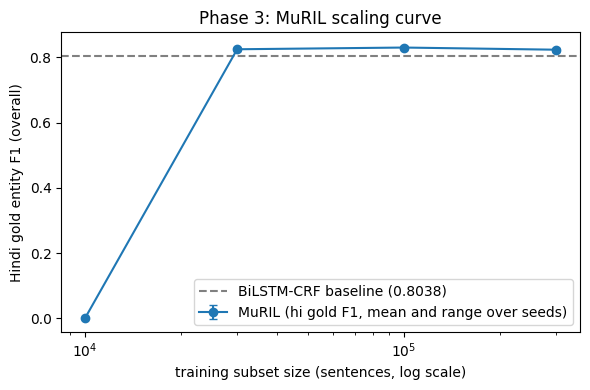

In [13]:
import matplotlib.pyplot as plt  # plotting library used to draw the F1-vs-training-size scaling curve
import pandas as pd  # used to load and filter results.csv as a DataFrame


def plot_scaling_curve():  # read the logged results, filter to just this run's real MuRIL curve rows, and plot F1 against training size
    results_df = pd.read_csv(os.path.join(REPO_ROOT, "results", "results.csv"))  # load every logged result row ever recorded across all phases/runs into a DataFrame
    curve_rows = results_df[  # filter down to only the rows that belong to this exact scaling-curve run
        (results_df["model"] == "MuRIL")  # only MuRIL rows -- IndicBERT is compared separately, not part of the curve
        & (results_df["train_lang"] == LANG)  # only rows trained on this notebook's language (Hindi)
        & (results_df["test_lang"] == LANG)  # only rows evaluated on Hindi as well (train_lang==test_lang, not a cross-lingual transfer row)
        & (results_df["epochs"] == EPOCHS)  # only rows using the standard epoch count, excluding the 9-epoch diagnosis and 10-epoch equal-steps control runs
        & (results_df["notes"].str.contains(f"lr={LR};", regex=False, na=False))  # only rows using the standard learning rate, excluding the 5e-5 diagnosis retry
        & (results_df["notes"].str.contains(f"git={GIT_COMMIT};", regex=False, na=False))  # only rows produced by this exact code commit, so stale results from an older version of the notebook can't sneak into the plot
        & (~results_df["notes"].str.contains("DEBUG", na=False))  # exclude any DEBUG-tagged rows, which are meaningless pipeline smoke-tests
    ]  # end of the boolean-mask filter applied to results_df
    curve = curve_rows.groupby("subset_size")["F1_overall"].agg(["mean", "min", "max", "count"]).reset_index()  # collapse the (possibly multi-seed) filtered rows into one summary row per subset size: mean/min/max F1 and how many seeds contributed

    if len(curve) == 0:  # nothing matched the filters -- most likely this is being run locally before the real Kaggle job has produced any matching rows
        print("No real (non-DEBUG) MuRIL rows logged yet -- run the scaling-curve cell on Kaggle first.")  # explain why there's nothing to plot, rather than crashing or silently producing an empty figure
    else:  # there is real data -- build the actual plot
        baseline_f1 = results_df.loc[  # look up the Phase 2 BiLSTM-CRF baseline score to draw as a reference line
            (results_df["model"] == "BiLSTM-CRF") & (~results_df["notes"].str.contains("DEBUG", na=False)),  # filter to non-DEBUG BiLSTM-CRF rows from the earlier phase
            "F1_overall",  # pull just the F1_overall column from the matching rows
        ].max()  # take the best logged BiLSTM-CRF score as the baseline to beat (in case more than one such row exists)
        fig, ax = plt.subplots(figsize=(6, 4))  # create a new figure and axes of a fixed, report-friendly size
        ax.errorbar(curve["subset_size"], curve["mean"],  # plot mean F1 at each subset size, with error bars showing the seed-to-seed spread
                    yerr=[curve["mean"] - curve["min"], curve["max"] - curve["mean"]],  # asymmetric error bars: distance from the mean down to the min and up to the max across seeds
                    marker="o", capsize=3, label="MuRIL (hi gold F1, mean and range over seeds)")  # draw a visible marker at each point, capped error-bar whiskers, and a legend label describing exactly what's plotted
        ax.axhline(baseline_f1, color="gray", linestyle="--", label=f"BiLSTM-CRF baseline ({baseline_f1:.4f})")  # draw a dashed horizontal reference line at the Phase 2 baseline F1, so MuRIL's improvement is visible directly on the chart
        ax.set_xscale("log")  # log-scale the x-axis since subset sizes span two orders of magnitude (10k to 300k)
        ax.set_xlabel("training subset size (sentences, log scale)")  # label the x-axis so the log scale isn't misread as linear
        ax.set_ylabel("Hindi gold entity F1 (overall)")  # label the y-axis with exactly what metric is being plotted
        ax.set_title("Phase 3: MuRIL scaling curve")  # give the figure a clear title identifying which phase/model it belongs to
        ax.legend()  # show the legend so the MuRIL curve and baseline line are both identified
        fig.tight_layout()  # adjust spacing automatically so labels/title aren't clipped
        fig_path = os.path.join(REPO_ROOT, "results", "phase3_scaling_curve.png")  # the fixed output path the gate script and README expect this figure at
        fig.savefig(fig_path, dpi=150)  # write the figure to disk at a resolution suitable for a report/README
        print("saved", fig_path)  # confirm where the figure was written
        print(curve.to_string(index=False))  # also print the underlying summary table, so the exact numbers behind the plot are visible in the executed notebook


# A plot failure must not stop the IndicBERT and handoff cells; it can be rebuilt from results.csv.
try:  # wrap the whole plotting step so a plotting bug can't derail the rest of the notebook (IndicBERT run, handoff verification)
    plot_scaling_curve()  # attempt to build and save the scaling-curve figure
except Exception as exc:  # catch absolutely any failure from plotting (bad data, missing matplotlib backend, etc.)
    print(f"WARNING: scaling plot failed ({exc!r})")  # report the failure clearly but let execution continue, since the plot can always be regenerated later from results.csv


## Choose the working subset size

Chosen by rule on **validation** F1, not by eye and not from the gold test
set: the smallest size with no collapsed seed whose mean validation F1 is
within `SIZE_TOLERANCE` of the best size. If the curve is still climbing
steeply at the largest size a Kaggle session allows, say so in
[docs/phase3/README.md](../docs/phase3/README.md) rather than forcing a
plateau that isn't there.

In [14]:
CHOSEN_SUBSET_SIZE = SUBSET_SIZES[0] if DEBUG else choose_subset_size(RUNS)  # in DEBUG mode just use the tiny debug size; for a real run, apply the documented selection rule to the collected RUNS
HANDOFF_RUN = next(r for r in RUNS if r["subset_size"] == CHOSEN_SUBSET_SIZE and r["seed"] == SEED)  # find the specific master-seed run at the chosen size -- this is the exact checkpoint Phase 4 will load
print("working subset size:", CHOSEN_SUBSET_SIZE)  # log the final chosen training-set size
print("handoff checkpoint:", HANDOFF_RUN["checkpoint_url"])  # log the exact checkpoint URL being handed off to the next phase


working subset size: 300000
handoff checkpoint: https://huggingface.co/priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s42_bfd254ed/tree/de5204680ed4a8ab1ac842847df6866a6e2c9251


## IndicBERT comparison (run on Kaggle, after choosing the size above)

One run at `CHOSEN_SUBSET_SIZE`, same harness, so MuRIL and IndicBERT are
compared at the same training size.

In [15]:
indicbert_run = train_run("IndicBERT", CHOSEN_SUBSET_SIZE)  # train IndicBERT once, at the same subset size MuRIL was ultimately chosen at, so the two models are compared on equal footing
print("IndicBERT scores:", indicbert_run["scores"])  # log IndicBERT's full score dict for direct comparison against MuRIL's at the same size
print("IndicBERT checkpoint:", indicbert_run["checkpoint_url"])  # log where the IndicBERT checkpoint was published, in case it's needed later



IndicBERT train subset n=300000: entities {'PER': 234007, 'ORG': 208992, 'LOC': 222599} | O = 82.1% of tokens | 90.5% of sentences have >=1 entity


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  135MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/23 [00:00<?, ?it/s]

[transformers] AlbertForTokenClassification LOAD REPORT from: ai4bharat/indic-bert
Key                              | Status     | 
---------------------------------+------------+-
sop_classifier.classifier.weight | UNEXPECTED | 
predictions.bias                 | UNEXPECTED | 
predictions.LayerNorm.bias       | UNEXPECTED | 
predictions.LayerNorm.weight     | UNEXPECTED | 
albert.pooler.bias               | UNEXPECTED | 
predictions.dense.bias           | UNEXPECTED | 
predictions.decoder.weight       | UNEXPECTED | 
predictions.decoder.bias         | UNEXPECTED | 
predictions.dense.weight         | UNEXPECTED | 
sop_classifier.classifier.bias   | UNEXPECTED | 
albert.pooler.weight             | UNEXPECTED | 
classifier.weight                | MISSING    | 
classifier.bias                  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missin

model.safetensors: reconstructing file:   0%|          |  0.00B /  135MB            

... (7 outputs left out)

epoch 3: val F1 0.7427


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

IndicBERT,hi,hi,300000,3,0.8537647790914747,0.6967741935483871,0.7692307692307692,0.7838528359734287,https://huggingface.co/priyadarshi-su/naamrekha-indicbert_hi_n300000_e3_lr2e-05_s42_3b287f89/tree/baacb700879d413a7712f4767398599154535d5c,seed=42; lr=2e-05; bs=32; effective_bs=32; gpus=1; warmup_steps=2812; epochs=3; max_len=128; checkpoint=ai4bharat/indic-bert; config=3b287f89; val_F1=0.7427; val_F1_by_epoch=0.7146/0.7346/0.7427; git=77b5e99; torch=2.11.0+cu130; transformers=5.22.1
published https://huggingface.co/priyadarshi-su/naamrekha-indicbert_hi_n300000_e3_lr2e-05_s42_3b287f89/tree/baacb700879d413a7712f4767398599154535d5c and removed the local copy
IndicBERT scores: {'F1_overall': 0.7838528359734287, 'F1_PER': 0.8537647790914747, 'F1_ORG': 0.6967741935483871, 'F1_LOC': 0.7692307692307692}
IndicBERT checkpoint: https://huggingface.co/priyadarshi-su/naamrekha-indicbert_hi_n300000_e3_lr2e-05_s42_3b287f89/tree/baacb700879d413a7712f4767398599154535d5c


## Verify the Phase 4 handoff checkpoint

Reloads the chosen MuRIL run from its pinned Hugging Face revision, re-scores
Hindi gold, and stops if the score does not match the logged row. Phase 4
should load this exact revision.

In [16]:
_repo_id, _revision = HANDOFF_RUN["repo_id"], HANDOFF_RUN["revision"]  # pull out the exact Hub repo id and pinned commit revision of the checkpoint Phase 4 is meant to load
_model = AutoModelForTokenClassification.from_pretrained(_repo_id, revision=_revision).to(device)  # reload the model fresh from the Hub at that exact pinned revision, not from any in-memory object, to simulate exactly what Phase 4 will do
_tok = AutoTokenizer.from_pretrained(_repo_id, revision=_revision)  # reload the matching tokenizer from the same pinned revision
_rescored = evaluate(*predict_tags(_model, _tok, test))["F1_overall"]  # re-run inference and scoring on the gold test set using only the reloaded checkpoint, independent of the in-memory training run
_logged = HANDOFF_RUN["scores"]["F1_overall"]  # the F1 that was already logged to results.csv for this run, to compare against
if abs(_rescored - _logged) > 1e-4:  # allow only floating-point-level numerical noise between the reload and the original run; anything larger signals a real mismatch
    raise RuntimeError(f"reloaded checkpoint scores {_rescored:.4f}, logged row says {_logged:.4f}")  # fail loudly if the published checkpoint doesn't reproduce its own logged score -- Phase 4 must not build on an unverified handoff
print(f"handoff verified: {_repo_id}@{_revision} re-scored {_rescored:.4f} (logged {_logged:.4f})")  # confirm the handoff checkpoint is good: reloadable from the Hub and reproduces its logged score exactly



config.json:   0%|          | 0.00/984 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  948MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/6.41M [00:00<?, ?B/s]

handoff verified: priyadarshi-su/naamrekha-muril_hi_n300000_e3_lr2e-05_s42_bfd254ed@de5204680ed4a8ab1ac842847df6866a6e2c9251 re-scored 0.8274 (logged 0.8274)


## Gate

Run from the repo root (locally -- this only reads committed files, no GPU
needed):

```
uv run python scripts/phase3_gate.py
```

It checks: every Phase 3 row comes from one top-to-bottom execution of one
commit, uses one GPU and warmup, and links to a pinned checkpoint; the chosen
size follows the validation-F1 rule and is confirmed on three seeds; the
handoff model was reloaded, re-scored, and clearly beats the Phase 2 baseline
(0.8038); an IndicBERT row exists at the chosen size; and the README, roadmap,
and decisions log agree with the result.